Index Number : 230038E

# Imports

In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib.patches as patches

In [2]:
def show_rgb(img, title="Image"):
    if img.ndim == 3:
        img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

    plt.figure(figsize=(6, 4))
    plt.imshow(img, cmap='gray' if img.ndim == 2 else None)
    plt.title(title)
    plt.axis('off')
    plt.show()

# Question 1

In [3]:
def intensity_transform(im, breakpoints):
    """
    Apply piecewise-linear intensity transformation.

    breakpoints:
        Nx2 array
        first column  = input intensity
        second column = output intensity
    """

    breakpoints = np.asarray(breakpoints, dtype=np.float32)

    x = breakpoints[:, 0]
    y = breakpoints[:, 1]

    transformed = np.interp(im.astype(np.float32), x, y)

    return np.clip(transformed, 0, 255).astype(np.uint8)

In [4]:
def plot_transformed(img, breakpoints, label=None):
    """
    Plot the original and transformed images along with the transformation function.
    """

    transformed = intensity_transform(img, breakpoints)

    plt.figure(figsize=(8, 3))

    plt.subplot(1, 3, 1)
    plt.imshow(img, cmap='gray')
    plt.title("Original Image")
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(transformed, cmap='gray')
    if label is not None:
        plt.title(f"{label}")
    else:
        plt.title("Transformed Image")
    plt.axis('off')

    plt.subplot(1, 3, 3)
    x = breakpoints[:, 0]
    y = breakpoints[:, 1]
    plt.plot(x, y, marker='o')
    plt.title("Transformation Function")
    plt.xlabel("Input Intensity")
    plt.ylabel("Output Intensity")
    plt.grid()

    plt.tight_layout()
    plt.show()

In [5]:
emma = cv.imread("Images/emma.jpg", cv.IMREAD_GRAYSCALE)

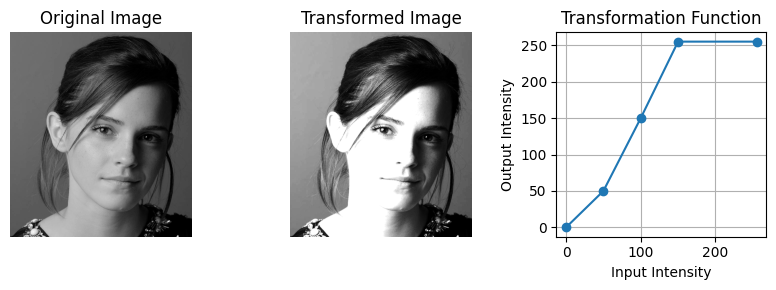

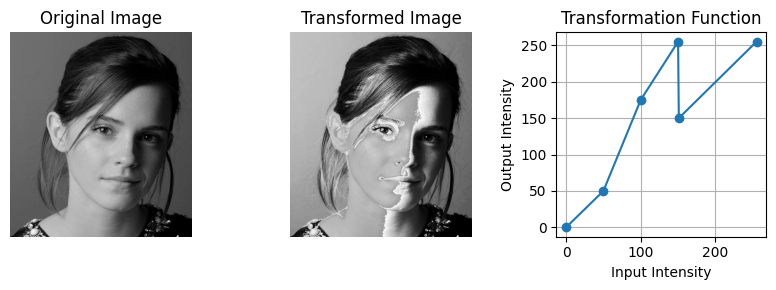

In [6]:
breakpoints1 = np.array([
    [0,   0],
    [50,  50],
    [100, 150],
    [150, 255],
    [255, 255]
])
breakpoints2 = np.array([
    [0, 0],
    [50,50],
    [100,175],
    [150,255],
    [151,150],
    [255,255]
])

plot_transformed(emma, breakpoints1)
plot_transformed(emma, breakpoints2)

# Question 2

[[ 1  1 10 ... 13 13  2]
 [ 1  1 10 ... 13 13  2]
 [ 1  1 10 ... 13 13  2]
 ...
 [ 9  9  8 ...  4  4  2]
 [ 9  9  8 ...  4  4  2]
 [ 9  9  8 ...  4  4  2]]


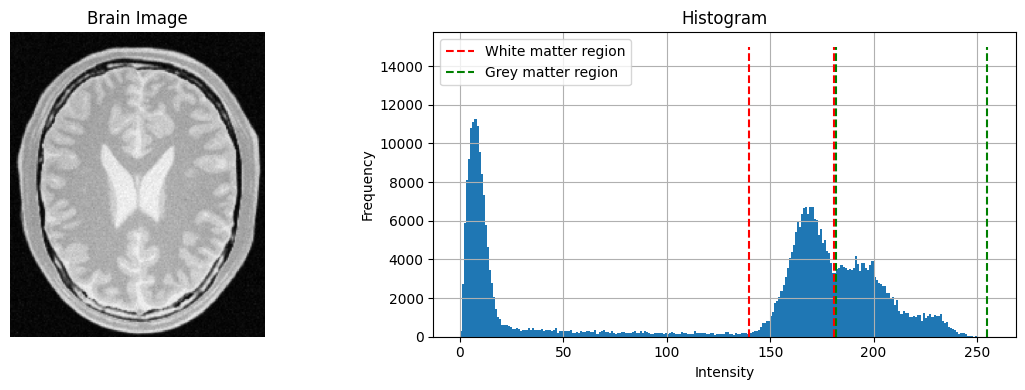

In [7]:
brain = cv.imread("Images/brain.png", cv.IMREAD_GRAYSCALE)
print(brain)
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(brain, cmap='gray')
plt.title("Brain Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.hist(brain.ravel(), bins=256, range=(0, 256))
plt.title("Histogram")
plt.xlabel("Intensity")
plt.ylabel("Frequency")
plt.grid(True)

ax1 = 140
plt.plot([ax1, ax1], [0, 15000], color='red', linestyle='--', label=f'White matter region')
ax2 = 181
plt.plot([ax2, ax2], [0, 15000], color='red', linestyle='--')
ax1 = 182
plt.plot([ax1, ax1], [0, 15000], color='green', linestyle='--', label=f'Grey matter region')
ax2 = 255
plt.plot([ax2, ax2], [0, 15000], color='green', linestyle='--')
plt.tight_layout()
plt.legend()
plt.show()

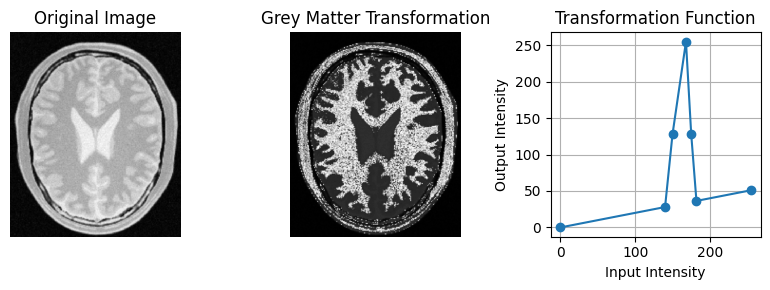

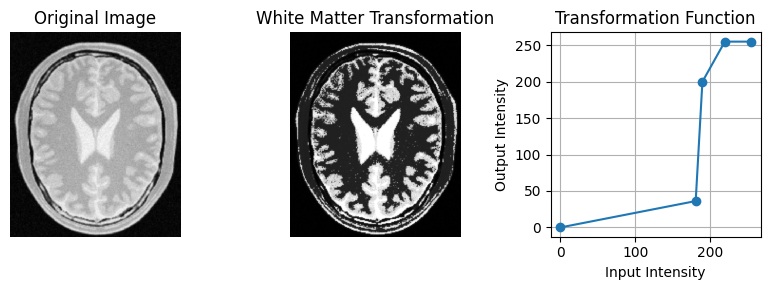

In [8]:
breakpoints_grey = np.array([
    [0, 0],
    [140, 140*0.2],
    [150, 128],
    [168, 255],
    [175, 128],
    [182, 182*0.2],
    [255, 255*0.2]
])
breakpoints_white = np.array([
    [0, 0],
    [181, 181*0.2],
    [190, 200],
    [220, 255],
    [255, 255]
])

plot_transformed(brain, breakpoints_grey, label="Grey Matter Transformation")
plot_transformed(brain, breakpoints_white, label="White Matter Transformation")

# Question 3

In [9]:
img = cv.imread("Images/q3.png")

lab = cv.cvtColor(img, cv.COLOR_BGR2LAB)

L, a, b = cv.split(lab)

gamma = 0.7

L_norm = L.astype(np.float32) / 255.0
L_gamma = 255 * (L_norm ** gamma)
L_gamma = np.clip(L_gamma, 0, 255).astype(np.uint8)

lab_corrected = cv.merge([L_gamma, a, b])

corrected = cv.cvtColor(lab_corrected, cv.COLOR_LAB2RGB)

Text(0.5, 1.0, 'Corrected')

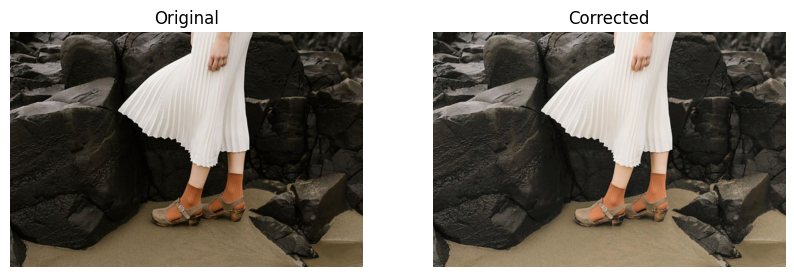

In [10]:
fig, ax = plt.subplots(1,2,figsize=(10, 5))
ax[0].imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
ax[0].axis("off")
ax[0].set_title("Original")
ax[1].imshow(corrected)
ax[1].axis("off")
ax[1].set_title("Corrected")

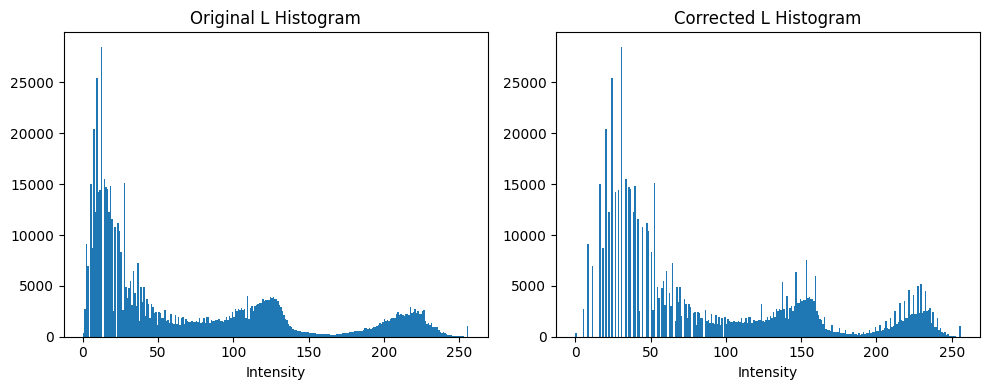

In [11]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.hist(L.ravel(), 256, [0,256])
plt.title("Original L Histogram")
plt.xlabel("Intensity")

plt.subplot(1, 2, 2)
plt.hist(L_gamma.ravel(), 256, [0,256])
plt.title("Corrected L Histogram")
plt.xlabel("Intensity")

plt.tight_layout()
plt.show()

# Question 4

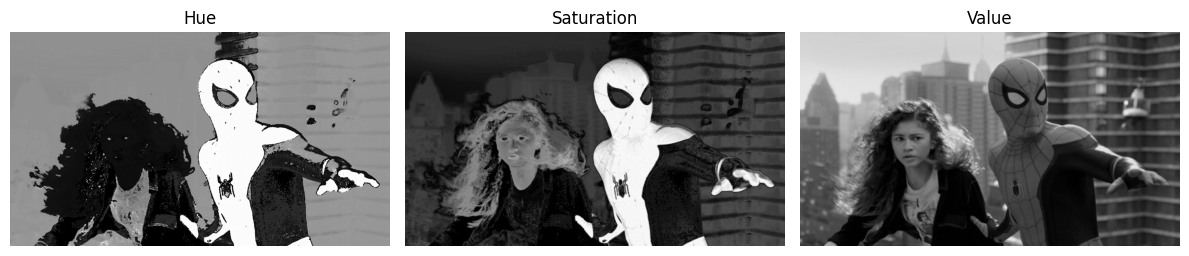

In [12]:
img = cv.imread("Images/spiderman.png")
hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)

H, S, V = cv.split(hsv)

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.imshow(H, cmap='gray')
plt.title("Hue")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(S, cmap='gray')
plt.title("Saturation")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(V, cmap='gray')
plt.title("Value")
plt.axis('off')

plt.tight_layout()
plt.show()

In [13]:
def plot_vibrance_transformation(S, sigma=70, a_value=0.0):
    x = S.astype(np.float32)

    S_new = x + a_value * 128 * np.exp(-((x - 128)**2) / (2 * sigma**2))
    
    S_new = np.clip(S_new, 0, 255).astype(np.uint8)
    x_plot = np.arange(256)

    y_plot = x_plot + a_value * 128 * np.exp(
        -((x_plot - 128)**2)/(2*sigma**2)
    )

    y_plot = np.clip(y_plot, 0, 255)
    plt.figure(figsize=(10, 4))

    plt.subplot(1, 3, 1)
    plt.plot(x_plot, y_plot)
    plt.xlabel("Input Saturation")
    plt.ylabel("Output Saturation")
    plt.title(f"Vibrance Transformation, a={a_value}")
    plt.grid()

    plt.subplot(1, 3, 2)
    plt.imshow(S, cmap='gray')
    plt.title("Original")
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(S_new, cmap='gray')
    plt.title(f"Vibrance Enhanced, a={a_value}")
    plt.axis('off')

    plt.tight_layout()
    plt.show()
    return S_new

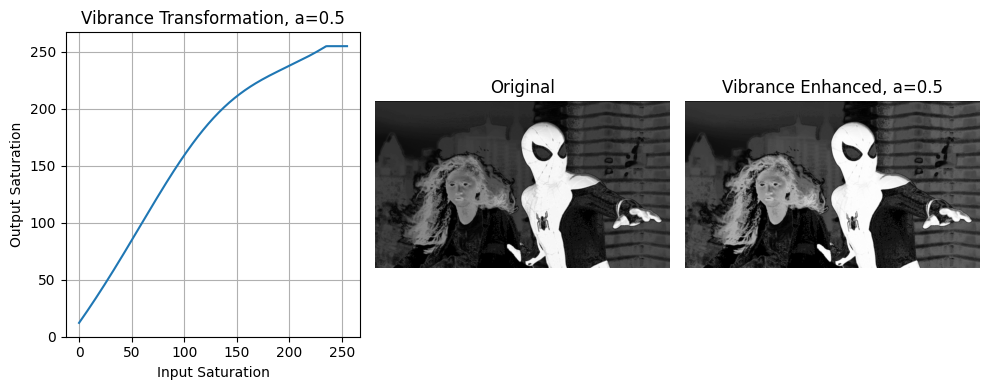

array([[12, 12, 12, ..., 12, 12, 12],
       [12, 12, 12, ..., 12, 12, 12],
       [51, 48, 48, ..., 52, 55, 59],
       ...,
       [43, 43, 49, ..., 96, 96, 90],
       [61, 61, 56, ..., 92, 92, 93],
       [56, 52, 52, ..., 93, 93, 93]], dtype=uint8)

In [14]:
plot_vibrance_transformation(S, sigma=70, a_value=0.5)

In [ ]:
for a in range(0, 11, 2):
    plot_vibrance_transformation(S, sigma=70, a_value=a/10)

As the value of $\textbf{a}$ is increase the colors of the image.

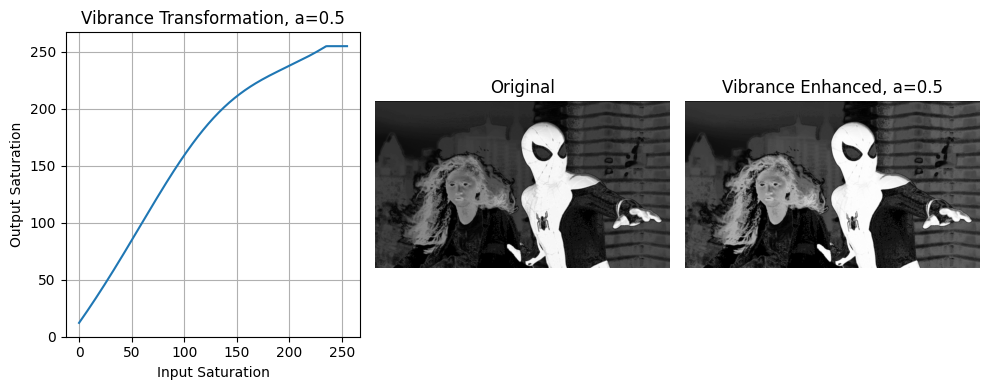

In [16]:
a_value = 0.5
modifiedImg = cv.merge([H, plot_vibrance_transformation(S, sigma=70, a_value=0.5), V])

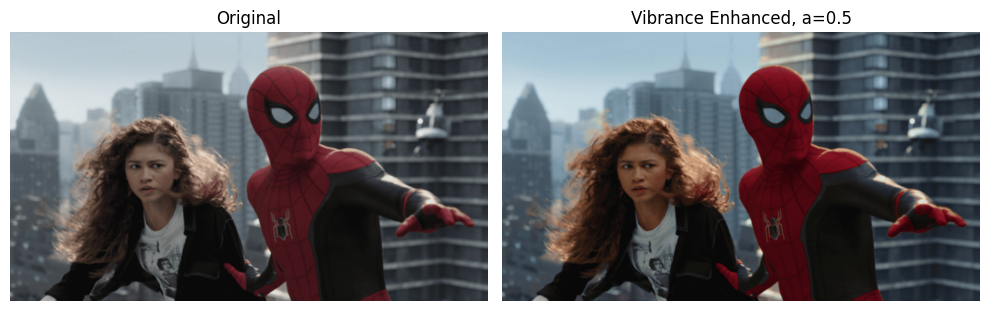

In [17]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title("Original")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(modifiedImg, cv.COLOR_HSV2RGB))
plt.title(f"Vibrance Enhanced, a={a_value}")
plt.axis('off')

plt.tight_layout()
plt.show()

# Question 5

In [18]:
img = cv.imread("Images/q5.tif", cv.IMREAD_GRAYSCALE)

In [19]:
def hist_equalization(img):
    hist = np.zeros(256)

    for pixel in img.ravel():
        hist[pixel] += 1

    pdf = hist / img.size
    cdf = np.cumsum(pdf)

    cdf_nonzero = cdf[cdf > 0]
    cdf_min = cdf_nonzero[0]

    mapping = np.round((cdf - cdf_min) /(cdf[-1] - cdf_min) * 255)

    mapping = np.clip(mapping, 0, 255).astype(np.uint8)
    return mapping[img]

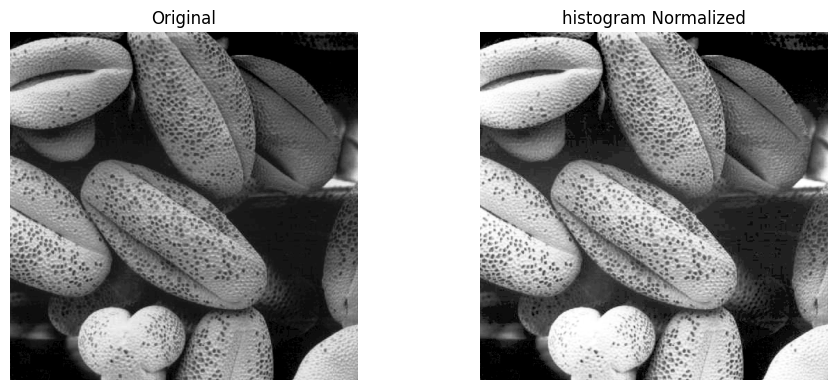

In [20]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="grey")
plt.title("Original")
plt.axis('off')

hist_norm = hist_equalization(img)
plt.subplot(1, 2, 2)
plt.imshow(hist_norm, cmap="grey")
plt.title(f"histogram Normalized")
plt.axis('off')

plt.tight_layout()
plt.show()


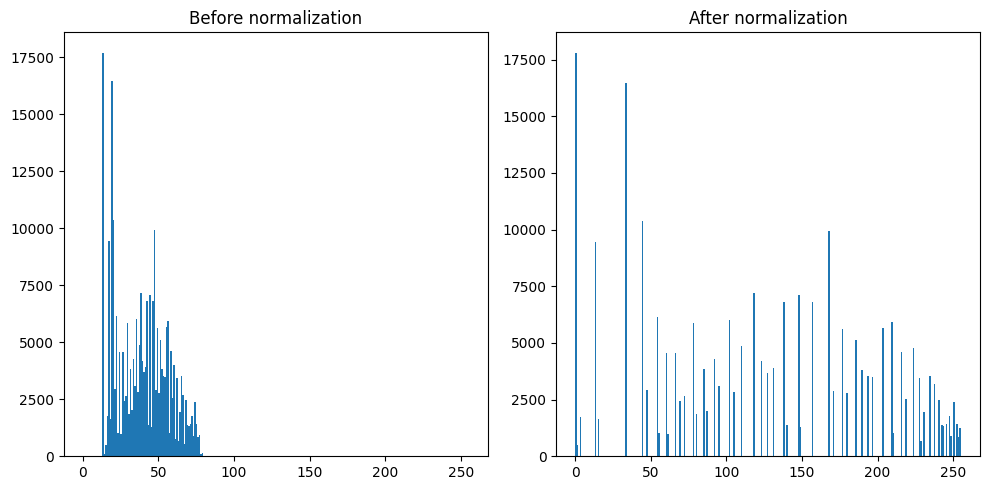

In [21]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.hist(img.ravel(), 256, (0,255))
plt.title("Before normalization")
plt.subplot(1,2,2)
plt.hist(hist_norm.ravel(), 256, (0,255))
plt.title("After normalization")

plt.tight_layout()
plt.show()

# Question 6

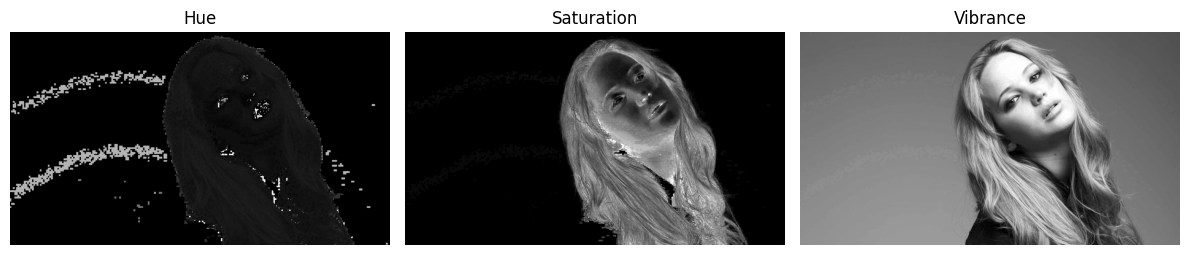

In [22]:
img = cv.imread("Images/q6.png", cv.IMREAD_COLOR_RGB)

H,S,V = cv.split(cv.cvtColor(img, cv.COLOR_RGB2HSV))
plt.figure(figsize=(12,6))
plt.subplot(1,3,1)
plt.imshow(H, cmap="grey")
plt.title("Hue")
plt.axis("off")
plt.subplot(1,3,2)
plt.imshow(S, cmap="grey")
plt.title("Saturation")
plt.axis("off")
plt.subplot(1,3,3)
plt.imshow(V, cmap="grey")
plt.title("Vibrance")
plt.axis("off")
plt.tight_layout()
plt.show()

Saturation plane is selected for seperation as it gives the highest contrast

Text(0.5, 1.0, 'mask')

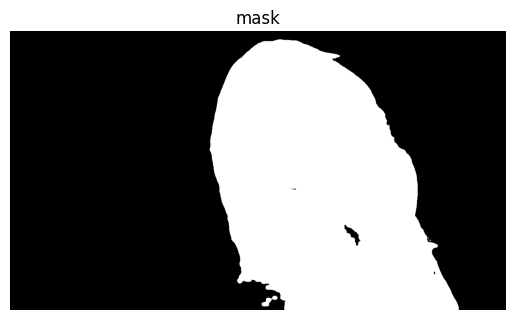

In [23]:
mask = np.array(cv.GaussianBlur(S, (11, 11), 20)>11, dtype=np.uint8)
plt.imshow(mask, cmap="grey")
plt.axis("off")
plt.title("mask")

In [24]:
foreground = cv.bitwise_and(img,img, mask=mask)
background = img - foreground

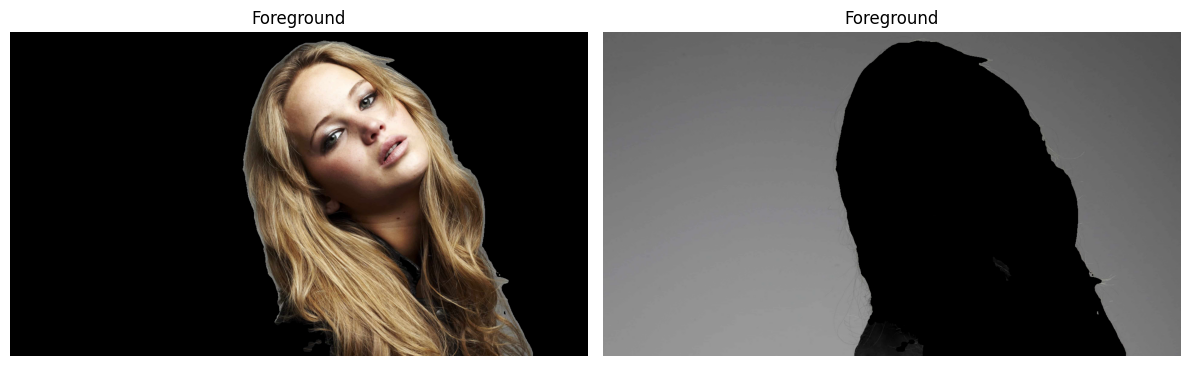

In [25]:
plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.imshow(foreground)
plt.title("Foreground")
plt.axis("off")
plt.subplot(1,2,2)
plt.imshow(background)
plt.title("Foreground")
plt.axis("off")

plt.tight_layout()
plt.show()

In [26]:
H,S,V = cv.split(cv.cvtColor(foreground, cv.COLOR_RGB2HSV))
norm_V = hist_equalization(V)
norm_fore = cv.cvtColor(cv.merge([H, S, norm_V]), cv.COLOR_HSV2RGB)

(0.0, 4000.0)

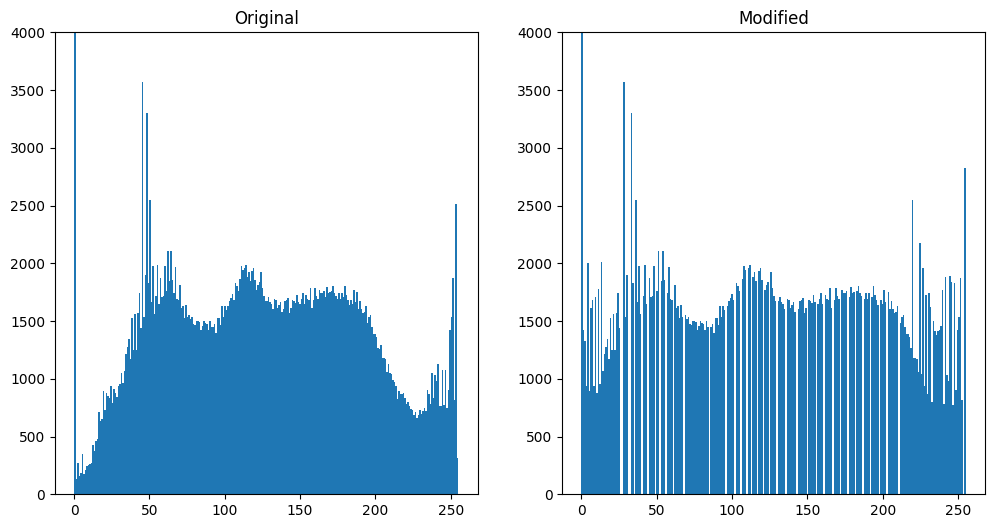

In [27]:
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.hist(V.ravel(), 256, (0,255))
plt.title("Original")
plt.ylim((0, 4000))
plt.subplot(1,2,2)
plt.hist(norm_V.ravel(), 256, (0,255))
plt.title("Modified")
plt.ylim((0, 4000))

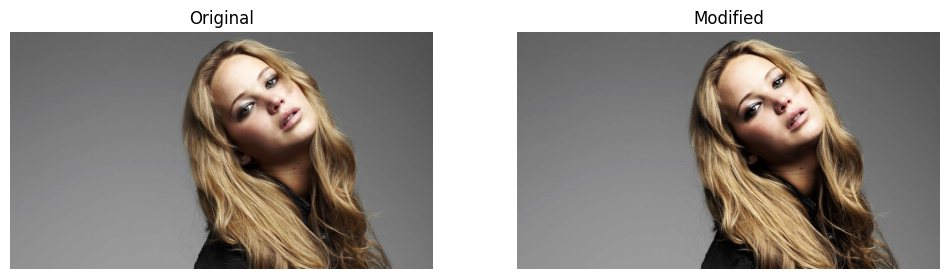

In [28]:

# plt.figure(figsize=(6,3))
# plt.imshow(mask, cmap="grey")
# plt.title("Mask")
# plt.axis("off")
# plt.show()

# plt.figure(figsize=(12,6))
# plt.subplot(1,3,1)
# plt.imshow(H, cmap="grey")
# plt.title("Hue of foreground")
# plt.axis("off")
# plt.subplot(1,3,2)
# plt.imshow(S, cmap="grey")
# plt.title("Saturation of foreground")
# plt.axis("off")
# plt.subplot(1,3,3)
# plt.imshow(norm_V, cmap="grey")
# plt.title("Vibrance of foreground")
# plt.axis("off")

# plt.tight_layout()
# plt.show()

plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.imshow(img)
plt.title("Original")
plt.axis("off")
plt.subplot(1,2,2)
plt.imshow(cv.add(background, norm_fore))
plt.title("Modified")
plt.axis("off")
plt.show()

# Question 7

In [29]:
img = cv.imread("Images/q7.png", cv.IMREAD_GRAYSCALE)

In [30]:
sobelX = np.array([[1,0,-1],
                   [2,0,-2],
                   [1,0,-1]])
sobelY = np.array([[1,2,1],
                   [0,0,0],
                   [-1,-2,-1]])
filteredX = cv.filter2D(img, cv.CV_32F, sobelX)
filteredY = cv.filter2D(img, cv.CV_32F, sobelY)

mag = cv.magnitude(filteredX, filteredY)

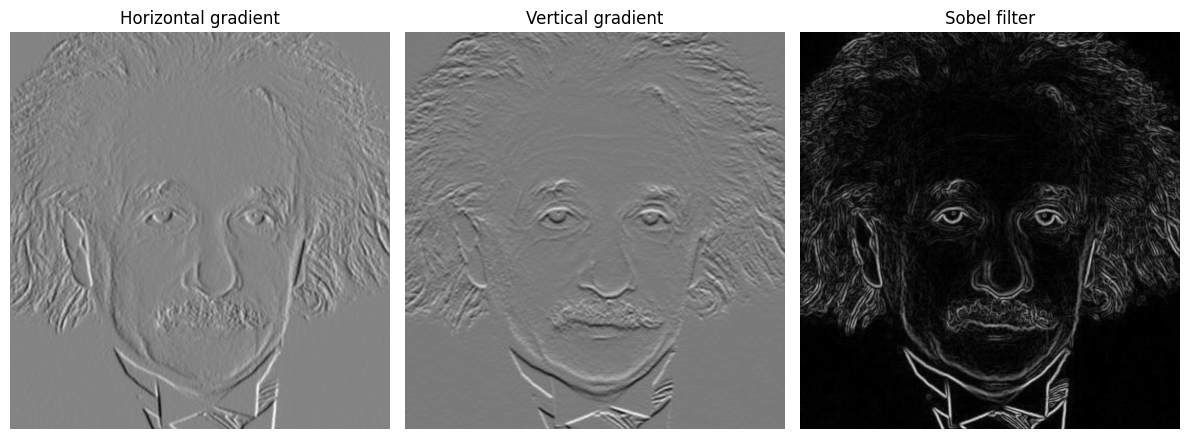

In [31]:
plt.figure(figsize=(12,6))
plt.subplot(1,3,1)
plt.imshow(filteredX, cmap="grey")
plt.title("Horizontal gradient")
plt.axis("off")
plt.subplot(1,3,2)
plt.imshow(filteredY, cmap="grey")
plt.title("Vertical gradient")
plt.axis("off")
plt.subplot(1,3,3)
plt.imshow(mag, cmap="grey")
plt.title("Sobel filter")
plt.axis("off")
plt.tight_layout()
plt.show()

In [32]:
def convolve2d(img, kernel):
    h, w = img.shape
    kh, kw = kernel.shape

    ph = kh // 2
    pw = kw // 2

    padded = np.pad(img,((ph,ph),(pw,pw)),mode='reflect')
    output = np.zeros((h,w), dtype=np.float32)

    for y in range(h):
        for x in range(w):
            region = padded[y:y+kh,x:x+kw]
            output[y,x] = np.sum(region * kernel)

    return output

In [33]:
filteredX_manual = convolve2d(img.astype(np.float32), sobelX)
filteredY_manual = convolve2d(img.astype(np.float32), sobelY)

mag_manual = np.sqrt(filteredX_manual**2 +filteredY_manual**2)

mag_manual = cv.normalize(mag_manual,None,0,255,cv.NORM_MINMAX).astype(np.uint8)

(-0.5, 804.5, 841.5, -0.5)

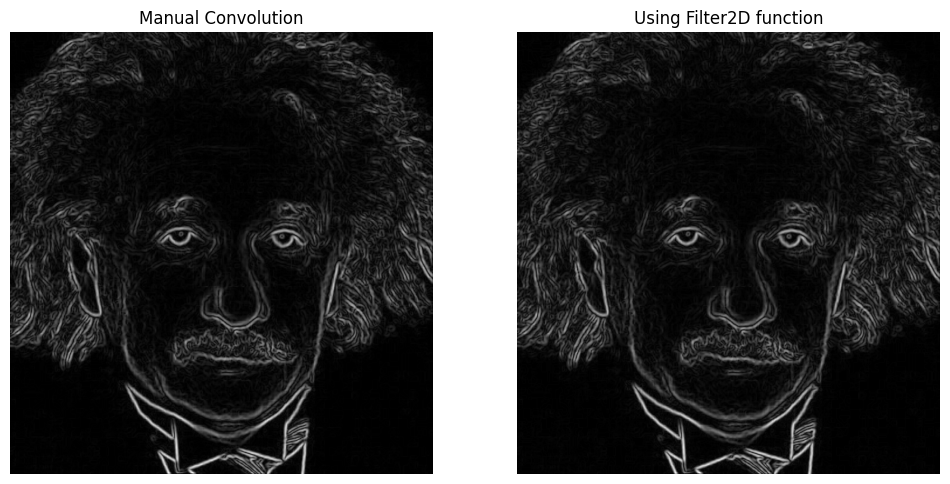

In [34]:
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.imshow(mag_manual, cmap="grey")
plt.title("Manual Convolution")
plt.axis("off")
plt.subplot(1,2,2)
plt.imshow(mag, cmap="grey")
plt.title("Using Filter2D function")
plt.axis("off")

In [35]:
kX1 = np.array([[1], [2], [1]])
kX2 = np.array([[1, 0, -1]])
kY1 = np.transpose(kX2)
kY2 = np.transpose(kX1)

oX1 = convolve2d(img.astype(np.float32), kX1)
X = convolve2d(oX1, kX2)
oY1 = convolve2d(img.astype(np.float32), kY1)
Y = convolve2d(oY1, kY2)

dual_manual = np.sqrt(X**2 +Y**2)

dual_manual = cv.normalize(dual_manual,None,0,255,cv.NORM_MINMAX).astype(np.uint8)

(-0.5, 804.5, 841.5, -0.5)

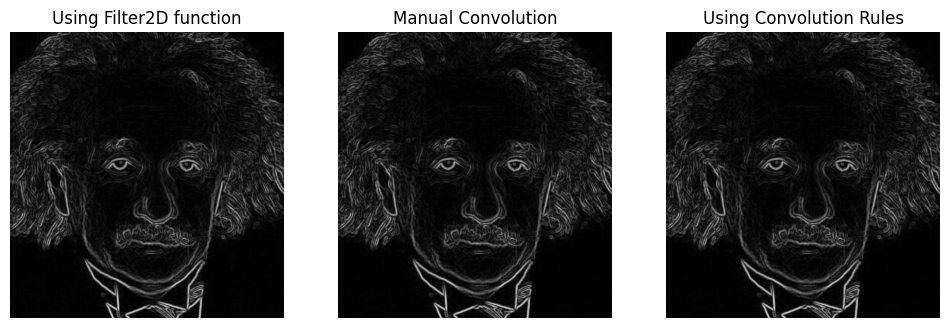

In [36]:
plt.figure(figsize=(12,6))
plt.subplot(1,3,3)
plt.imshow(dual_manual, cmap="grey")
plt.title("Using Convolution Rules")
plt.axis("off")
plt.subplot(1,3,1)
plt.imshow(mag, cmap="grey")
plt.title("Using Filter2D function")
plt.axis("off")
plt.subplot(1,3,2)
plt.imshow(mag_manual, cmap="grey")
plt.title("Manual Convolution")
plt.axis("off")

# Question 8

In [37]:
def zoom_nearest(img, scale):

    if scale <= 0 or scale > 10:
        raise ValueError("Scale must be in (0, 10]")

    h, w = img.shape[:2]

    new_h = int(round(h * scale))
    new_w = int(round(w * scale))

    output = np.zeros((new_h, new_w) + img.shape[2:],dtype=img.dtype)

    for y in range(new_h):
        for x in range(new_w):

            src_y = min(int(round(y / scale)), h-1)
            src_x = min(int(round(x / scale)), w-1)

            output[y,x] = img[src_y,src_x]

    return output

In [38]:
def zoom_bilinear(img, scale):

    if scale <= 0 or scale > 10:
        raise ValueError("Scale must be in (0,10]")

    h, w = img.shape[:2]

    new_h = int(round(h * scale))
    new_w = int(round(w * scale))

    output = np.zeros((new_h, new_w) + img.shape[2:],dtype=np.float32)

    for y in range(new_h):
        src_y = y / scale

        y0 = int(np.floor(src_y))
        y1 = min(y0 + 1, h-1)

        dy = src_y - y0

        for x in range(new_w):
            src_x = x / scale

            x0 = int(np.floor(src_x))
            x1 = min(x0 + 1, w-1)

            dx = src_x - x0

            top = ((1-dx)*img[y0,x0].astype(np.float32)+ dx*img[y0,x1].astype(np.float32))

            bottom = ((1-dx)*img[y1,x0].astype(np.float32)+ dx*img[y1,x1].astype(np.float32))

            output[y,x] = ((1-dy)*top +dy*bottom)

    return np.clip(output,0,255).astype(np.uint8)

In [39]:
def normalized_ssd(img1, img2):

    img1 = img1.astype(np.float64)
    img2 = img2.astype(np.float64)

    return np.mean(((img1-img2)/255.0)**2)

In [40]:
data = []
for i in range(1, 5):
    small = cv.imread(f"Images/im0{i}small.png", cv.IMREAD_COLOR_RGB)
    original = cv.imread(f"Images/im0{i}.png", cv.IMREAD_COLOR_RGB)
    if small is None:
        small = cv.imread(f"Images/im0{i}small.jpg", cv.IMREAD_COLOR_RGB)
        original = cv.imread(f"Images/im0{i}.jpg", cv.IMREAD_COLOR_RGB)

    print(f"Images/im0{i}small.png")
    nn = zoom_nearest(small, 4)
    bilinear = zoom_bilinear(small, 4)

    # In case rounding gives 1 pixel mismatch
    original = cv.resize(original,(nn.shape[1], nn.shape[0]))

    ssd_nn = normalized_ssd(original, nn)
    ssd_bilinear = normalized_ssd(original, bilinear)

    data.append({"img": f"im0{i}", "nn SSD": ssd_nn, "bilinear SSD" : ssd_bilinear})

data = pd.DataFrame(data)

Images/im01small.png
Images/im02small.png
Images/im03small.png
Images/im04small.png


In [41]:
data

,img,nn SSD,bilinear SSD
0,im01,0.003926,0.003080
1,im02,0.000994,0.000753
2,im03,0.002222,0.001693
3,im04,0.006304,0.005063


In [42]:
print(f"On average bilinear interpolation performs {round(((data["nn SSD"] - data["bilinear SSD"])/data["nn SSD"]*100).mean(), 2)}% better than nearest neighbour")

On average bilinear interpolation performs 22.32% better than nearest neighbour


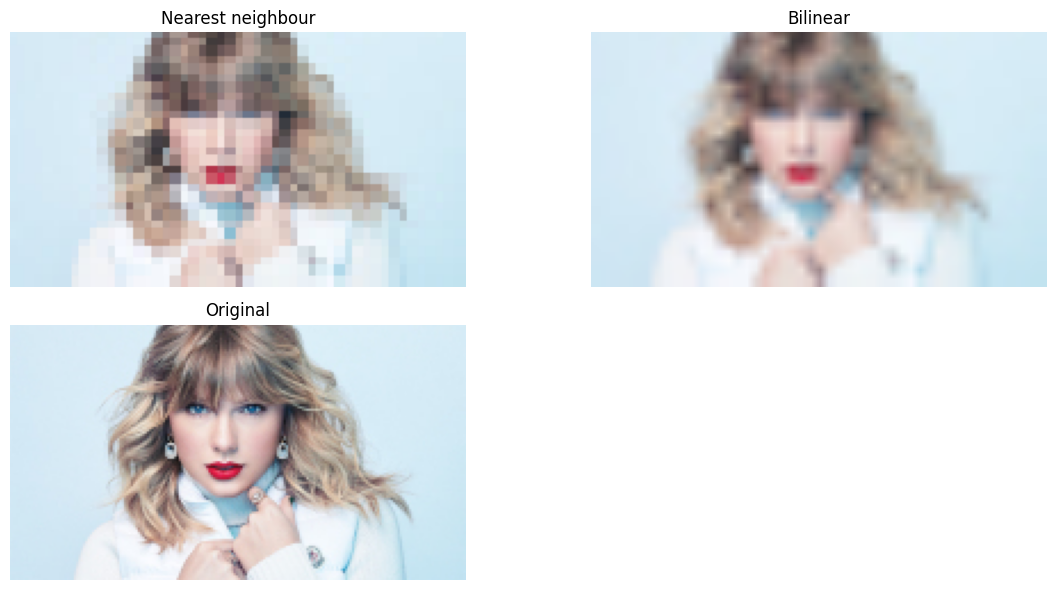

In [43]:
plt.figure(figsize=(12,6))

plt.subplot(2,2,1)
plt.imshow(nn)
plt.title("Nearest neighbour")
plt.axis("off")

plt.subplot(2,2,2)
plt.imshow(bilinear)
plt.title("Bilinear")
plt.axis("off")

plt.subplot(2,2,3)
plt.imshow(original)
plt.title("Original")
plt.axis("off")

plt.tight_layout()
plt.show()

# Question 9

In [44]:
img = cv.imread("Images/q9_flower.jpeg", cv.IMREAD_COLOR_RGB)

mask = np.zeros(img.shape[:2], np.uint8)

bgModel = np.zeros((1,65), np.float64)
fgModel = np.zeros((1,65), np.float64)

h, w = img.shape[:2]

rect = (int(0.07*w),int(0.15*h),int(0.99*w),int(0.5*h))

# patch = patches.Rectangle((rect[0], rect[1]),rect[2]-rect[0],rect[3],linewidth=2,edgecolor="r",alpha = 0.5)

# fig, ax = plt.subplots()

# ax.imshow(img)
# ax.add_patch(patch)
# ax.axis("off")

In [ ]:
cv.grabCut(img,mask,rect,bgModel,fgModel,5,cv.GC_INIT_WITH_RECT)

In [46]:
final_mask = np.where(
    (mask == cv.GC_FGD) |
    (mask == cv.GC_PR_FGD),
    1,
    0
).astype(np.uint8)

foreground = final_mask[:,:,None]
background = (1-final_mask)[:,:,None]

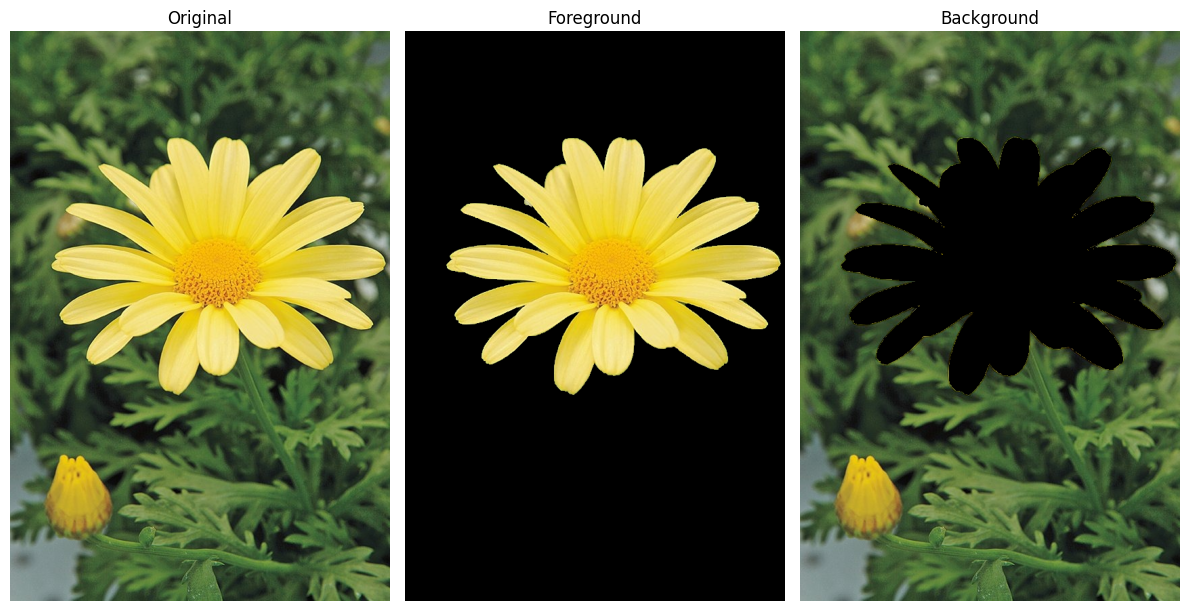

In [47]:
plt.figure(figsize=(12,6))

plt.subplot(1,3,1)
plt.imshow(img)
plt.title("Original")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(img*foreground)
plt.title("Foreground")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(img*background)
plt.title("Background")
plt.axis("off")

plt.tight_layout()
plt.show()

In [48]:
final_img = img*foreground + cv.GaussianBlur(img*background, (11,11), 5)

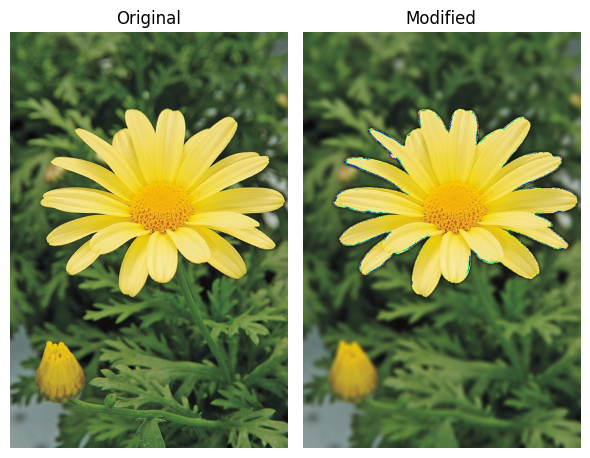

In [49]:
plt.figure(figsize=(6,6))

plt.subplot(1,2,1)
plt.imshow(img)
plt.title("Original")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(final_img)
plt.title("Modified")
plt.axis("off")

plt.tight_layout()
plt.show()


In the background image the part where the flower is is replaced with black. Once the blurring is done that black spills to the background and discolors the surrounding.

# Question 10

In [50]:
img = cv.imread("Images/q10_lake.jpeg")

sigma_s = 5
sigma_r = 30

bilateral_cv = cv.bilateralFilter(img,d=11,sigmaColor=sigma_r,sigmaSpace=sigma_s)
gaussian = cv.GaussianBlur(img,(11,11),sigma_s)

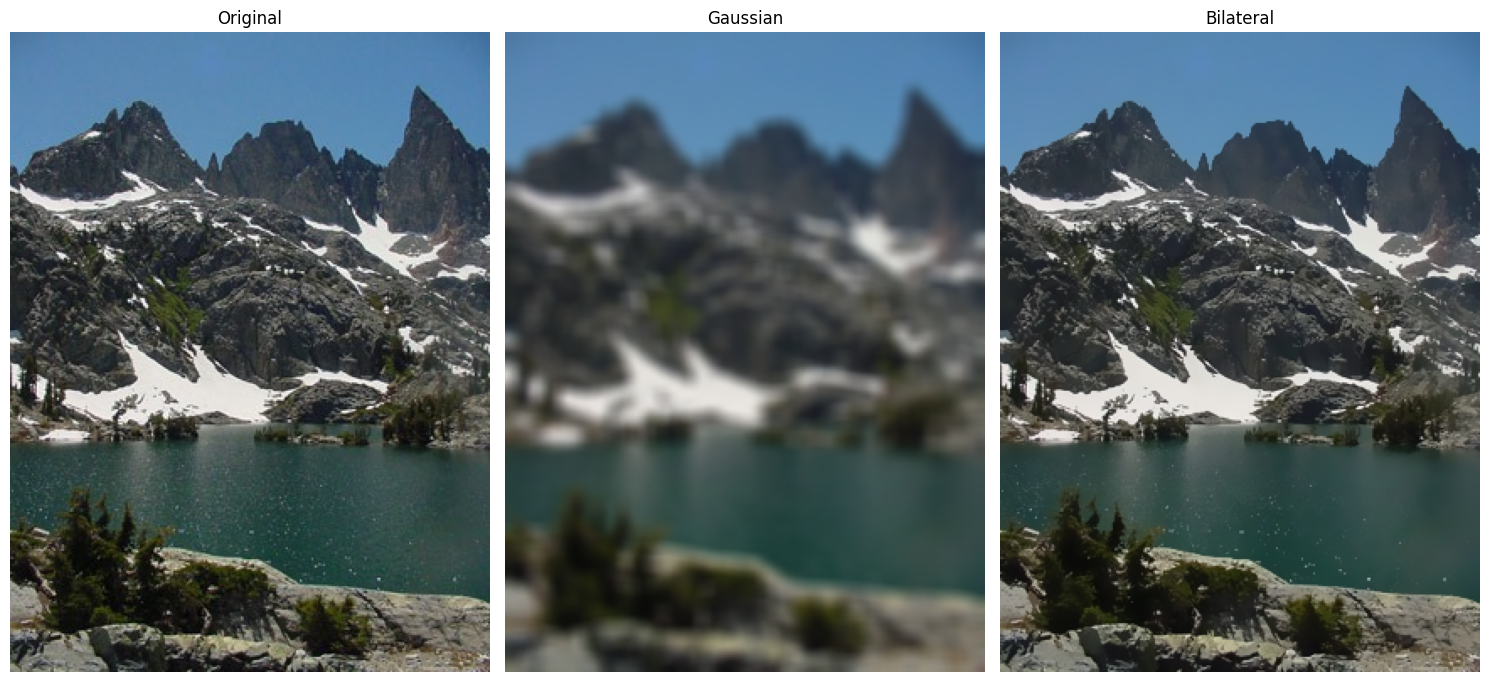

In [51]:
#region: Plotting
plt.figure(figsize=(15,7))

plt.subplot(1,3,1)
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title("Original")
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(cv.cvtColor(gaussian, cv.COLOR_BGR2RGB))
plt.title("Gaussian")
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(cv.cvtColor(bilateral_cv, cv.COLOR_BGR2RGB))
plt.title("Bilateral")
plt.axis('off')
#endregion
plt.tight_layout()
plt.show()

In [52]:
def bilateral_filter_manual(img,kernel_size=7,sigma_space=5,sigma_range=30):
    img = img.astype(np.float32)

    h, w, c = img.shape
    r = kernel_size // 2

    padded = cv.copyMakeBorder(img,r, r, r, r,cv.BORDER_REFLECT)
    output = np.zeros_like(img)

    yy, xx = np.mgrid[-r:r+1,-r:r+1]
    spatial_weights = np.exp(-(xx**2 + yy**2) /(2*sigma_space**2))

    for y in range(h):
        for x in range(w):
            centre = padded[y+r, x+r]
            region = padded[y:y+kernel_size,x:x+kernel_size]
            # Euclidean RGB distance
            diff = region - centre

            range_distance = np.sum(diff**2,axis=2)

            range_weights = np.exp(-range_distance /(2*sigma_range**2))

            weights = (spatial_weights *range_weights)

            weights_sum = np.sum(weights)

            for channel in range(3):
                output[y,x,channel] = np.sum(region[:,:,channel] *weights) / weights_sum

    return np.clip(output,0,255).astype(np.uint8)

In [53]:
bilateral_manual = bilateral_filter_manual(img, kernel_size=11, sigma_space=5, sigma_range=30 )

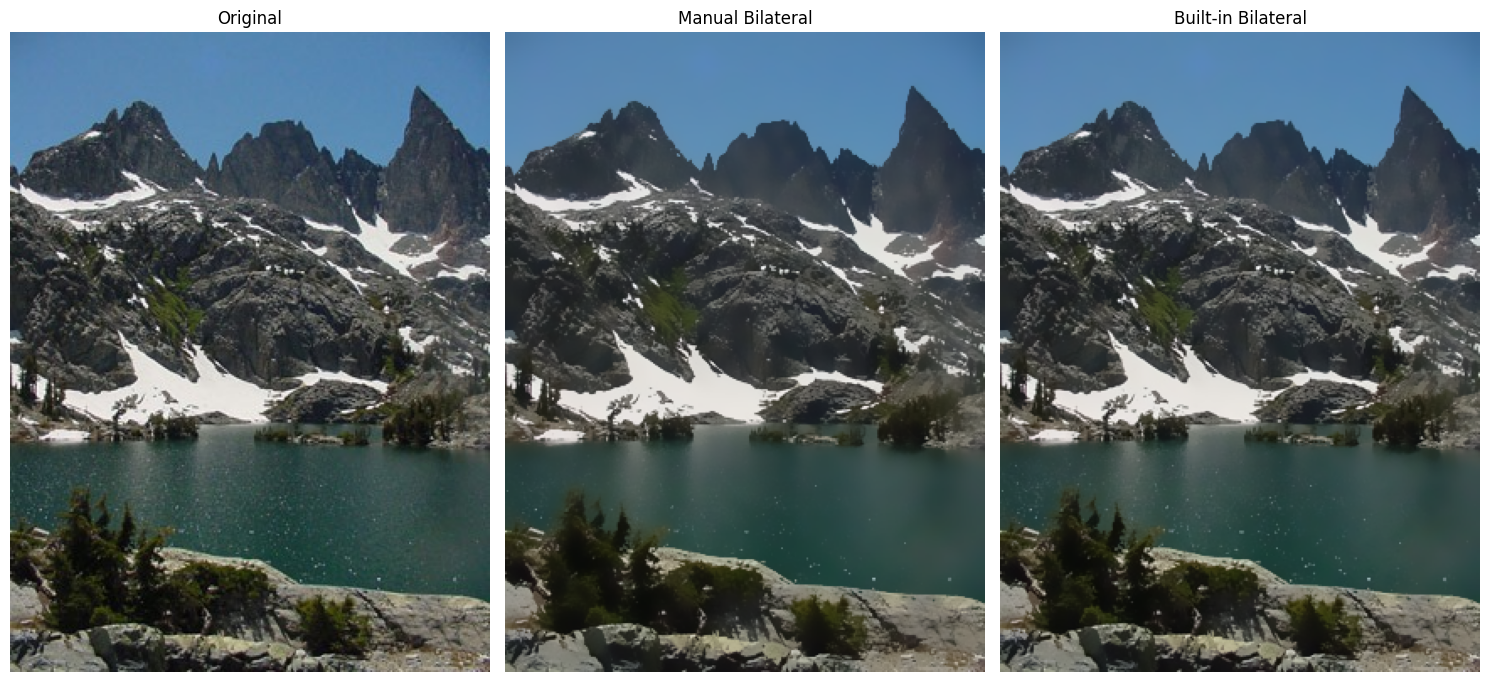

In [54]:
#region: Plottingz
plt.figure(figsize=(15,7))

plt.subplot(1,3,1)
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title("Original")
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(cv.cvtColor(bilateral_manual, cv.COLOR_BGR2RGB))
plt.title("Manual Bilateral")
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(cv.cvtColor(bilateral_cv, cv.COLOR_BGR2RGB))
plt.title("Built-in Bilateral")
plt.axis('off')
#endregion
plt.tight_layout()
plt.show()

In [55]:
normalized_ssd(bilateral_cv, bilateral_manual)

0.0001331043331701506

Given the same paramters the manual only varies by $\textbf{0.00013}$ in terms of normalized sum of squares (SSD). Which means there is only a small difference in the manual implementation and CV2 implementation